In [1]:
import math
import numpy as np
import pandas as pd
from scipy.stats import norm
from scipy.integrate import quad

In [2]:
df = pd.read_csv(
    r"D:\FRM2\outputs\byd_ifind_20261027\002594_SZ_close_af_20211101_20261026.csv",
    encoding="utf-8-sig",
    parse_dates=["trade_date"],  # 将日期列转为日期类型
    dtype={"thscode": str},      # 股票代码按字符串读取
)
df["modified_price"] = df['ths_close_price_stock'] * df['ths_af_stock'] #添加复权因子调整后的价格
df["position"] = 10000 #添加头寸
rng = np.random.default_rng(42)
df["interim_payments"] = rng.integers(-10000,10001, size = len(df))#添加持有期间发生的现金支付或收入
df["book_value"] = df['modified_price'] * df['position']
df["discount_rate"] = 0.02
print(df.head())   # 查看前 5 行
print(df.dtypes)   # 查看各列类型
print(df.shape)    # 应为 (1208, 4)

  trade_date    thscode  ths_close_price_stock  ths_af_stock  modified_price  \
0 2021-11-01  002594.SZ                 302.00      1.020391      308.158025   
1 2021-11-02  002594.SZ                 313.88      1.020391      320.280268   
2 2021-11-03  002594.SZ                 303.01      1.020391      309.188620   
3 2021-11-04  002594.SZ                 325.00      1.020391      331.627013   
4 2021-11-05  002594.SZ                 314.00      1.020391      320.402715   

   position  interim_payments    book_value  discount_rate  
0     10000             -8215  3.081580e+06           0.02  
1     10000              5479  3.202803e+06           0.02  
2     10000              3092  3.091886e+06           0.02  
3     10000             -1222  3.316270e+06           0.02  
4     10000             -1340  3.204027e+06           0.02  
trade_date               datetime64[us]
thscode                             str
ths_close_price_stock           float64
ths_af_stock                    f

In [3]:
from pnl_calculator import cal_pnl, cal_pvpnl, cal_fvpnl
result = cal_pnl(df)
result = cal_pvpnl(result)
result = cal_fvpnl(result)
result

,trade_date,thscode,ths_close_price_stock,ths_af_stock,modified_price,position,interim_payments,book_value,discount_rate,pnl,pvpnl,fvpnl
0,2021-11-01,002594.SZ,302.00,1.020391,308.158025,10000,-8215,3.081580e+06,0.02,NaN,NaN,NaN
1,2021-11-02,002594.SZ,313.88,1.020391,320.280268,10000,5479,3.202803e+06,0.02,126701.428299,126446.822976,126456.858438
2,2021-11-03,002594.SZ,303.01,1.020391,309.188620,10000,3092,3.091886e+06,0.02,-107824.481112,-108070.094809,-108078.671801
3,2021-11-04,002594.SZ,325.00,1.020391,331.627013,10000,-1222,3.316270e+06,0.02,223161.939251,222898.861072,222916.551458
4,2021-11-05,002594.SZ,314.00,1.020391,320.402715,10000,-1340,3.204027e+06,0.02,-113582.989166,-113837.150514,-113846.185208
...,...,...,...,...,...,...,...,...,...,...,...,...
1203,2026-10-20,002594.SZ,82.60,3.162336,261.208913,10000,5229,2.612089e+06,0.02,-23232.019581,-23439.726757,-23441.587053
1204,2026-10-21,002594.SZ,80.70,3.162336,255.200476,10000,3018,2.552005e+06,0.02,-57066.374671,-57269.138162,-57273.683332
1205,2026-10-22,002594.SZ,80.02,3.162336,253.050087,10000,8067,2.530501e+06,0.02,-13436.881461,-13638.339113,-13639.421521
1206,2026-10-23,002594.SZ,81.42,3.162336,257.477357,10000,302,2.574774e+06,0.02,44574.697126,44370.342268,44373.863723


In [4]:
from ret_calculator import cal_arithmetic_return, cal_geometric_return
result = cal_arithmetic_return(result)
result = cal_geometric_return(result)
result

,trade_date,thscode,ths_close_price_stock,ths_af_stock,modified_price,position,interim_payments,book_value,discount_rate,pnl,pvpnl,fvpnl,arithmetic_return,geometric_return
0,2021-11-01,002594.SZ,302.00,1.020391,308.158025,10000,-8215,3.081580e+06,0.02,NaN,NaN,NaN,NaN,NaN
1,2021-11-02,002594.SZ,313.88,1.020391,320.280268,10000,5479,3.202803e+06,0.02,126701.428299,126446.822976,126456.858438,0.041116,0.040293
2,2021-11-03,002594.SZ,303.01,1.020391,309.188620,10000,3092,3.091886e+06,0.02,-107824.481112,-108070.094809,-108078.671801,-0.033666,-0.034245
3,2021-11-04,002594.SZ,325.00,1.020391,331.627013,10000,-1222,3.316270e+06,0.02,223161.939251,222898.861072,222916.551458,0.072177,0.069691
4,2021-11-05,002594.SZ,314.00,1.020391,320.402715,10000,-1340,3.204027e+06,0.02,-113582.989166,-113837.150514,-113846.185208,-0.034250,-0.034851
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1203,2026-10-20,002594.SZ,82.60,3.162336,261.208913,10000,5229,2.612089e+06,0.02,-23232.019581,-23439.726757,-23441.587053,-0.008798,-0.008837
1204,2026-10-21,002594.SZ,80.70,3.162336,255.200476,10000,3018,2.552005e+06,0.02,-57066.374671,-57269.138162,-57273.683332,-0.021847,-0.022089
1205,2026-10-22,002594.SZ,80.02,3.162336,253.050087,10000,8067,2.530501e+06,0.02,-13436.881461,-13638.339113,-13639.421521,-0.005265,-0.005279
1206,2026-10-23,002594.SZ,81.42,3.162336,257.477357,10000,302,2.574774e+06,0.02,44574.697126,44370.342268,44373.863723,0.017615,0.017462


In [5]:
from VaR_calculator import cal_historical_var, cal_normal_var, cal_lognormal_var
HSVaR_95 = cal_historical_var(result, confidence_level=0.95, target_column="pnl")
print(f"Historical PnL VaR at 95% confidence level is {HSVaR_95}")
NpnlVaR_95 = cal_normal_var(result, confidence_level=0.95, target_column="arithmetic_return")
print(f"Normal Return VaR at 95% confidence level is {NpnlVaR_95}")
LretVaR_95 = cal_lognormal_var(result, confidence_level=0.95, target_column="geometric_return")
print(f"Log-Normal Return VaR at 95% confidence level is {LretVaR_95}")

Historical PnL VaR at 95% confidence level is 90865.34486912051
Normal Return VaR at 95% confidence level is 0.03571934191609268
Log-Normal Return VaR at 95% confidence level is 0.035172086117918


In [6]:
from Coherent_Risk_calculator import HistoricalLossQuantile, ExpectedShortfall

data = result[["pnl"]].dropna()

loss_quantile = HistoricalLossQuantile(
    data,
    target_column="pnl",
)

es = ExpectedShortfall(
    loss_quantile,
    confidence_level=0.95,
).calculate()

es

134263.4590668807

In [7]:
from se_calculator import quantile_standard_error, bin_density, spectral_standard_error, empirical_expected_shortfall, bootstrap_standard_error
import pandas as pd
from statistics import NormalDist
# 假设上述函数已导入
normal = NormalDist()

p = 0.95
q = normal.inv_cdf(p)

inputs = pd.DataFrame({
    "quantile": [q],
    "probability": [p],
    "density_at_quantile": [normal.pdf(q)],
})

result = quantile_standard_error(
    inputs,
    quantile_column="quantile",
    probability_column="probability",
    density_column="density_at_quantile",
    sample_size=1000,
    confidence_level=0.90,
)

display(result)

,quantile,probability,density_at_quantile,variance,standard_error,ci_lower,ci_upper
0,1.644854,0.95,0.103136,0.004466,0.066825,1.534937,1.754771


In [8]:
h = 0.1

bin_inputs = pd.DataFrame({
    "quantile": [q],
    "probability": [p],
    "cdf_lower": [normal.cdf(q - h / 2)],
    "cdf_upper": [normal.cdf(q + h / 2)],
    "bin_width": [h],
})

with_density = bin_density(
    bin_inputs,
    lower_cdf_column="cdf_lower",
    upper_cdf_column="cdf_upper",
    bin_width_column="bin_width",
)

bin_result = quantile_standard_error(
    with_density,
    quantile_column="quantile",
    probability_column="probability",
    density_column="density",
    sample_size=1000,
    confidence_level=0.90,
)

display(bin_result)

,quantile,probability,cdf_lower,cdf_upper,bin_width,density,variance,standard_error,ci_lower,ci_upper
0,1.644854,0.95,0.944628,0.954948,0.1,0.103209,0.004459,0.066777,1.535015,1.754693


In [9]:
a = 0.95
n_nodes = 1000
dp = (1.0 - a) / n_nodes

probabilities = a + (np.arange(n_nodes) + 0.5) * dp
quantiles = np.array([normal.inv_cdf(x) for x in probabilities])
densities = np.array([normal.pdf(x) for x in quantiles])

nodes = pd.DataFrame({
    "probability": probabilities,
    "quantile": quantiles,
    "density": densities,
    "spectrum": 1.0 / (1.0 - a),
    "integration_weight": dp,
})

es_result = spectral_standard_error(
    nodes,
    probability_column="probability",
    quantile_column="quantile",
    density_column="density",
    spectrum_column="spectrum",
    integration_weight_column="integration_weight",
    sample_size=1000,
    confidence_level=0.90,
)

display(es_result)

# 标准正态 ES 的解析值，可用于检查积分精度
exact_es = normal.pdf(normal.inv_cdf(a)) / (1.0 - a)
print("解析 ES:", exact_es)
print("积分误差:", es_result["estimate"] - exact_es)

estimate          2.062637
variance          0.006080
standard_error    0.077971
ci_lower          1.934386
ci_upper          2.190889
dtype: float64

解析 ES: 2.062712807507429
积分误差: -7.544008705862026e-05


In [10]:
data = pd.DataFrame({
    "loss": np.random.default_rng(42).normal(size=1000),
})

var_bootstrap = bootstrap_standard_error(
    data,
    estimator=lambda sample: sample["loss"].quantile(0.95),
    n_resamples=2000,
    rng=np.random.default_rng(100),
    confidence_level=0.90,
)

es_bootstrap = bootstrap_standard_error(
    data,
    estimator=lambda sample: empirical_expected_shortfall(
        sample,
        target_column="loss",
        probability=0.95,
    ),
    n_resamples=2000,
    rng=np.random.default_rng(101),
    confidence_level=0.90,
)

display(pd.DataFrame({
    "VaR": var_bootstrap,
    "ES": es_bootstrap,
}))

,VaR,ES
estimate,1.616243,2.004169
bootstrap_mean,1.620719,2.002628
bootstrap_bias,0.004477,-0.001542
standard_error,0.066602,0.072593
normal_ci_lower,1.506692,1.884765
normal_ci_upper,1.725794,2.123574
percentile_ci_lower,1.495756,1.889161
percentile_ci_upper,1.728995,2.123446


,value
n,500.000000
mean,-0.006011
median,0.010437
histogram_mode,-0.029447
standard_deviation,1.370162
skewness,-0.007452
kurtosis,6.947189
excess_kurtosis,3.947189
minimum,-5.419019
maximum,7.413295


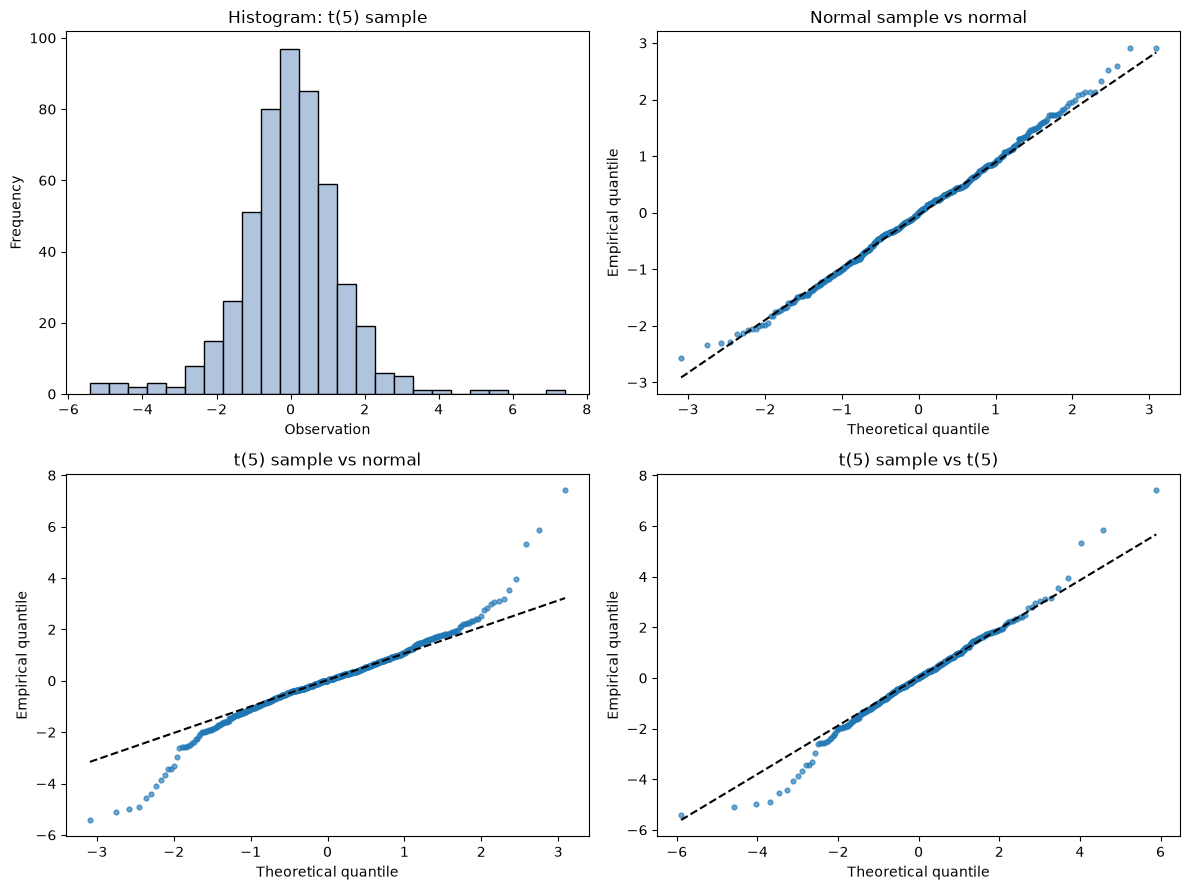

In [11]:
from preliminary_DA import *

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# 假设前面的计算函数已经导入
rng = np.random.default_rng(42)

data = pd.DataFrame({
    "normal_sample": rng.normal(size=500),
    "t_sample": rng.standard_t(df=5, size=500),
})

# 调用层选择直方图边界
bin_edges = np.histogram_bin_edges(data["t_sample"], bins=25)

histogram = histogram_table(
    data,
    target_column="t_sample",
    bin_edges=bin_edges,
)

summary = summary_statistics(
    data,
    target_column="t_sample",
    mode_bin_edges=bin_edges,
)

qq_normal = qq_coordinates(
    data,
    target_column="normal_sample",
    reference_distribution=stats.norm(),
)

qq_t_against_normal = qq_coordinates(
    data,
    target_column="t_sample",
    reference_distribution=stats.norm(),
)

qq_t_against_t = qq_coordinates(
    data,
    target_column="t_sample",
    reference_distribution=stats.t(df=5),
)

display(summary.to_frame("value"))

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

axes[0, 0].bar(
    histogram["bin_left"],
    histogram["count"],
    width=histogram["bin_width"],
    align="edge",
    color="lightsteelblue",
    edgecolor="black",
)
axes[0, 0].set(
    title="Histogram: t(5) sample",
    xlabel="Observation",
    ylabel="Frequency",
)

qq_panels = [
    (axes[0, 1], qq_normal, "Normal sample vs normal"),
    (axes[1, 0], qq_t_against_normal, "t(5) sample vs normal"),
    (axes[1, 1], qq_t_against_t, "t(5) sample vs t(5)"),
]

for ax, coordinates, title in qq_panels:
    ax.scatter(
        coordinates["theoretical_quantile"],
        coordinates["empirical_quantile"],
        s=12,
        alpha=0.65,
    )
    ax.plot(
        coordinates["theoretical_quantile"],
        coordinates["reference_line"],
        linestyle="--",
        color="black",
    )
    ax.set(
        title=title,
        xlabel="Theoretical quantile",
        ylabel="Empirical quantile",
    )

fig.tight_layout()
plt.show()

In [12]:
# 直方图概率之和为 1
assert np.isclose(histogram["probability"].sum(), 1.0)

# 概率密度乘区间宽度的总和为 1
assert np.isclose(
    (histogram["density"] * histogram["bin_width"]).sum(),
    1.0,
)

# 两种峰度口径相差 3
assert np.isclose(
    summary["kurtosis"] - summary["excess_kurtosis"],
    3.0,
)

# 标准 t(5) 分布的总体理论值，供比较
theoretical_t5 = pd.Series({
    "mean": 0.0,
    "standard_deviation": np.sqrt(5 / 3),
    "skewness": 0.0,
    "kurtosis": 9.0,
    "excess_kurtosis": 6.0,
})

display(theoretical_t5.to_frame("population_value"))

,population_value
mean,0.000000
standard_deviation,1.290994
skewness,0.000000
kurtosis,9.000000
excess_kurtosis,6.000000


In [ ]:
"""
待完善
"""
def mean_excess(
    data: pd.DataFrame,
    target_column: str,
    thresholds: pd.DataFrame,
    threshold_column: str,
) -> pd.DataFrame:
    """计算右尾平均超额；没有超阈值观测时，结果为 NaN。"""
    result = thresholds.copy()
    values = data[target_column]

    counts = []
    excess_means = []

    for threshold in result[threshold_column]:
        excess = values[values > threshold] - threshold
        counts.append(len(excess))
        excess_means.append(excess.mean())

    result["exceedance_count"] = counts
    result["mean_excess"] = excess_means

    return result
